In [1]:
import re
import string

import requests

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

# pytorch
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F

import time

torch.manual_seed(42)

In [ ]:
# use this utility to preprocess the text (sentence); returns the cleaned text as a single string

def preprocess(text, min_len=2):
    strings2replace = [ '\r\n\r\nâ\x80\x9c','â\x80\x9c','â\x80\x9d','\r\n','â\x80\x94','â\x80\x99','â\x80\x98','_']
    for s in strings2replace:
        regexp = re.compile(s)
        text = regexp.sub(" ", text)

    text = re.sub(r'[^\x00-\x7F]+', ' ', text) # non ASCII characters
    text = re.sub(r'\d+','',text).lower() # digits
    
    words = re.split(fr'[{string.punctuation}\s]+',text)
    words = [item.strip() for item in words if item.strip()]
    words = [item for item in words if len(item) >= min_len]

    return " ".join(words)

In [2]:
url = "https://www.gutenberg.org/files/35/35-0.txt"
text = preprocess(requests.get(url).text)
print(text[:1000])

start of the project gutenberg ebook the time machine an invention by wells contents introduction ii the machine iii the time traveller returns iv time travelling in the golden age vi the sunset of mankind vii sudden shock viii explanation ix the morlocks when night came xi the palace of green porcelain xii in the darkness xiii the trap of the white sphinx xiv the further vision xv the time traveller return xvi after the story epilogue introduction the time traveller for so it will be convenient to speak of him was expounding recondite matter to us his grey eyes shone and twinkled and his usually pale face was flushed and animated the fire burnt brightly and the soft radiance of the incandescent lights in the lilies of silver caught the bubbles that flashed and passed in our glasses our chairs being his patents embraced and caressed us rather than submitted to be sat upon and there was that luxurious after dinner atmosphere when thought runs gracefully free of the trammels of precision

In [3]:
words = text.split()

vocab = sorted(set(words))

n_words = len(words)
n_vocab = len(vocab)

word2idx = {word : i for i, word in enumerate(vocab)}
idx2word = {i : word for i, word in enumerate(vocab)}

print(f"Total words: {n_words}, unique words: {n_vocab}")

Total words: 30699, unique words: 4589


In [4]:
class WordDataset(Dataset):
    def __init__(self, words, word2idx, context_size=8, stride=4):
        self.inputs, self.targets = [], []
        self.word2idx = word2idx

        for i in range(0, len(words)-context_size, stride):
            input_seq = words[i: i+context_size]
            target_seq = words[i+1: i+1+context_size]
        
            self.inputs.append(torch.tensor([word2idx[word] for word in input_seq]))
            self.targets.append(torch.tensor([word2idx[word] for word in target_seq]))

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx]

context_size, stride = 6, 3
words_dataset = WordDataset(words=words, word2idx=word2idx, context_size=context_size, stride=stride)
print(len(words_dataset))
print(words_dataset[22])

dl = DataLoader(words_dataset, batch_size=32, shuffle=True, drop_last=True)
batch_x, batch_y = next(iter(dl))
print(batch_x.shape)
print(batch_y.shape)

10231
(tensor([4371, 4567, 4042, 4109, 4171, 3306]), tensor([4567, 4042, 4109, 4171, 3306, 4568]))
torch.Size([32, 6])
torch.Size([32, 6])


In [5]:
class EmbeddingsModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, context_size):
        super().__init__()

        # embedding layer
        self.embeddings = nn.Embedding(vocab_size, embedding_dim) # builds the look-up table: shape as (vocab_size, embedding_dim) # (input_dims, output_dims)

        # hidden layer
        self.linear1 = nn.Linear(context_size*embedding_dim, 128)
        self.linear2 = nn.Linear(128, vocab_size)

    def forward(self, x): # initially x.shape = (batch_size, context_size) 
        embeds = self.embeddings(x).view(x.shape[0], -1) # shape: (batch_size, context_size, embedding_dim) -> (batch_size, context_size*embedding_dim) # flattened and ready to go to linear layer
        out = F.relu(self.linear1(embeds)) # shape: (batch_size, 128)
        out = self.linear2(out) # shape: (batch, vocab)

        return F.log_softmax(out, dim=1)
        
    

model = EmbeddingsModel(vocab_size=n_vocab, embedding_dim=100, context_size=6)
print(model)

EmbeddingsModel(
  (embeddings): Embedding(4589, 100)
  (linear1): Linear(in_features=600, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=4589, bias=True)
)


In [6]:
n_vocab, d_model, context_size = len(vocab), 100, 6
training_epochs, learning_rate = 50, 0.001

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EmbeddingsModel(vocab_size=n_vocab, embedding_dim=d_model, context_size=context_size)
model.to(device)                                   

criterion = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=.01)

losses = torch.zeros(training_epochs)

START = time.time()
for epoch in range(training_epochs):
    epoch_loss = 0.0
    for X, y in dl:
        X, y = X.to(device), y.to(device)           
        optimizer.zero_grad()
        output = model(X)
        loss = criterion(output, y[:, -1])
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    losses[epoch] = epoch_loss / len(dl)
    print(f"Epoch: {epoch+1}, loss: {losses[epoch]:.4f}")
END = time.time()
print(f"Finished in {END - START} seconds.")

Epoch: 1, loss: 6.8888
Epoch: 2, loss: 5.3352
Epoch: 3, loss: 4.4313
Epoch: 4, loss: 3.2481
Epoch: 5, loss: 1.9488
Epoch: 6, loss: 1.0582
Epoch: 7, loss: 0.5689
Epoch: 8, loss: 0.3058
Epoch: 9, loss: 0.1609
Epoch: 10, loss: 0.0885
Epoch: 11, loss: 0.0539
Epoch: 12, loss: 0.0391
Epoch: 13, loss: 0.0295
Epoch: 14, loss: 0.0244
Epoch: 15, loss: 0.0225
Epoch: 16, loss: 0.0195
Epoch: 17, loss: 0.0149
Epoch: 18, loss: 0.0165
Epoch: 19, loss: 0.0148
Epoch: 20, loss: 0.0137
Epoch: 21, loss: 0.0155
Epoch: 22, loss: 0.0160
Epoch: 23, loss: 0.0212
Epoch: 24, loss: 0.0298
Epoch: 25, loss: 0.0216
Epoch: 26, loss: 0.0193
Epoch: 27, loss: 0.0104
Epoch: 28, loss: 0.0073
Epoch: 29, loss: 0.0085
Epoch: 30, loss: 0.0037
Epoch: 31, loss: 0.0056
Epoch: 32, loss: 0.0067
Epoch: 33, loss: 0.0058
Epoch: 34, loss: 0.0056
Epoch: 35, loss: 0.0032
Epoch: 36, loss: 0.0029
Epoch: 37, loss: 0.0041
Epoch: 38, loss: 0.0066
Epoch: 39, loss: 0.1069
Epoch: 40, loss: 0.0258
Epoch: 41, loss: 0.0066
Epoch: 42, loss: 0.0030
E

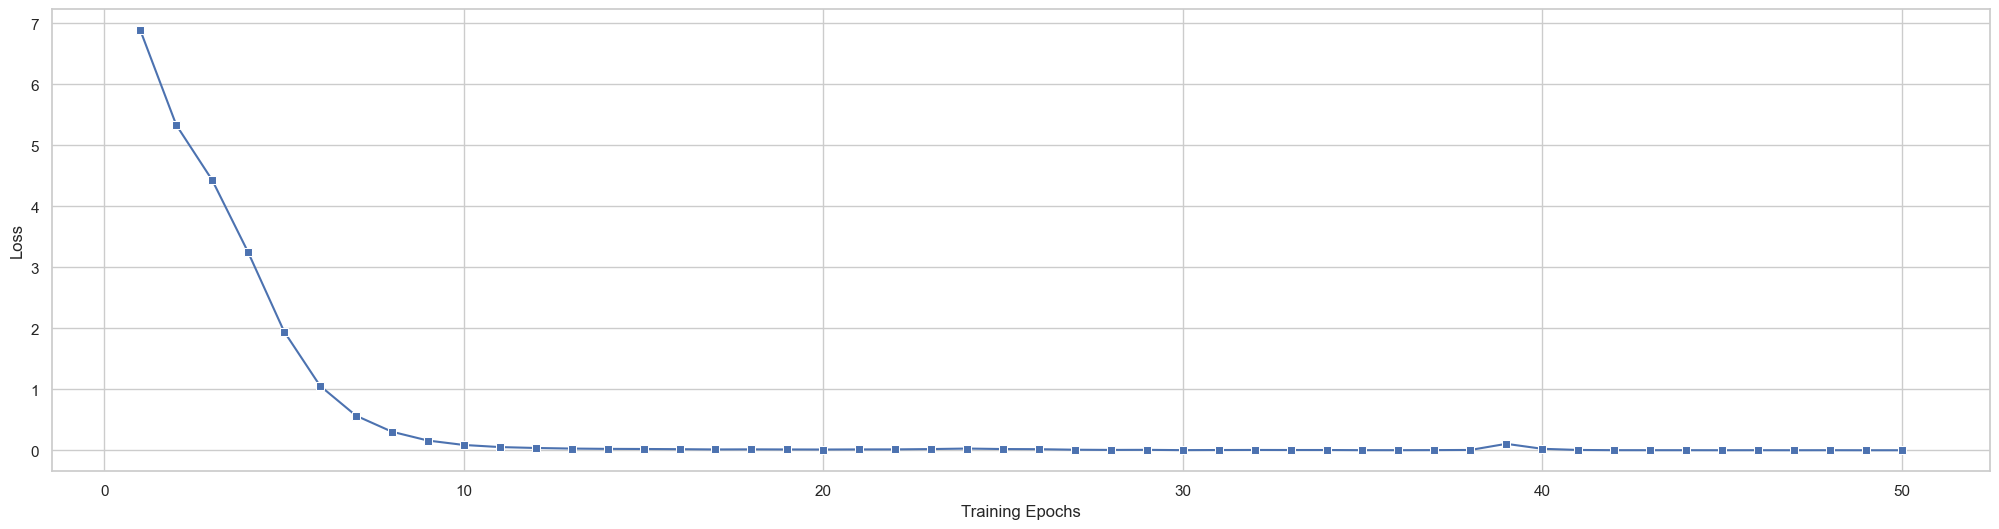

In [8]:
plt.figure(figsize=(25, 6))
sns.lineplot(x=range(1, training_epochs+1), y=losses, marker="s")
plt.xlabel("Training Epochs")
plt.ylabel("Loss");

In [9]:
losses[-1]

tensor(0.0019)